# Ćwiczenie 12 (Część 1): Rejestracja elastyczna / niesztywna (Deformable Registration)

Na poprzednich zajęciach zajmowaliśmy się **rejestracją sztywną (Rigid)**, w której cały obraz traktowaliśmy jak nieodkształcalną bryłę (np. kości czaszki) – mogliśmy go jedynie przesunąć i obrócić jedną globalną macierzą.

W praktyce klinicznej narządy wewnętrzne są jednak **miękkie i elastyczne**:
* Płuca zmieniają kształt i objętość podczas cyklu oddechowego.
* Pęcherz moczowy i jelita wypełniają się i przemieszczają między kolejnymi sesjami radioterapii.
* Guzy nowotworowe rosną lub kurczą się pod wpływem chemioterapii.

W takich sytuacjach żadna globalna rotacja ani translacja nie wystarczy – potrzebujemy **rejestracji elastycznej (niesztywnej)**.

---

## Kluczowe pojęcia teoretyczne

1. **Pole wektorowe odkształceń (Displacement Field):**
   Zamiast jednej macierzy dla całego zdjęcia, każdy piksel $(x, y)$ otrzymuje własny wektor przesunięcia $\vec{u}(x, y) = [dx, dy]$, wskazujący dokąd przemieściła się dana cząstka tkanki.

2. **Transformacja B-splajn (Free-Form Deformation – FFD):**
   Gdybyśmy pozwolili każdemu pikselowi poruszać się zupełnie niezależnie, algorytm mógłby sztucznie "rozerwać" anatomię. Dlatego na obraz nakładamy rzadszą **siatkę punktów kontrolnych (Control Point Grid)** – niczym elastyczną gumową siatkę. Optymalizator przesuwa jedynie węzły tej siatki, a ruch pikseli pomiędzy nimi jest gładko interpolowany za pomocą wielomianów B-sklejanych (B-splines). Gwarantuje to ciągłość i fizyczną realizm odkształceń.

In [2]:
#!pip install SimpleITK

import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt

print(f"Wersja SimpleITK: {sitk.__version__}")

Wersja SimpleITK: 2.5.7


## 1. Budowa syntetycznego fantomu medycznego i lokalnej deformacji

Aby dobrze zrozumieć działanie deformacji lokalnych, stworzymy syntetyczny przekrój anatomiczny zawierający:
* **Zewnętrzny obrys ciała** (elipsa).
* **Kręgosłup** na dole (struktura kostna, która powinna pozostać nieruchoma).
* **Dwa narządy / obszary tkanek miękkich** wewnątrz, z czego lewy narząd ulegnie lokalnemu obrzękowi / powiększeniu (np. podczas wdechu lub wzrostu zmiany).
* **Binarną maskę segmentacyjną** lewego narządu – sprawdzimy na końcu, jak rejestracja pozwala automatycznie przenosić kontury z jednego badania na drugie (*Mask Propagation*).

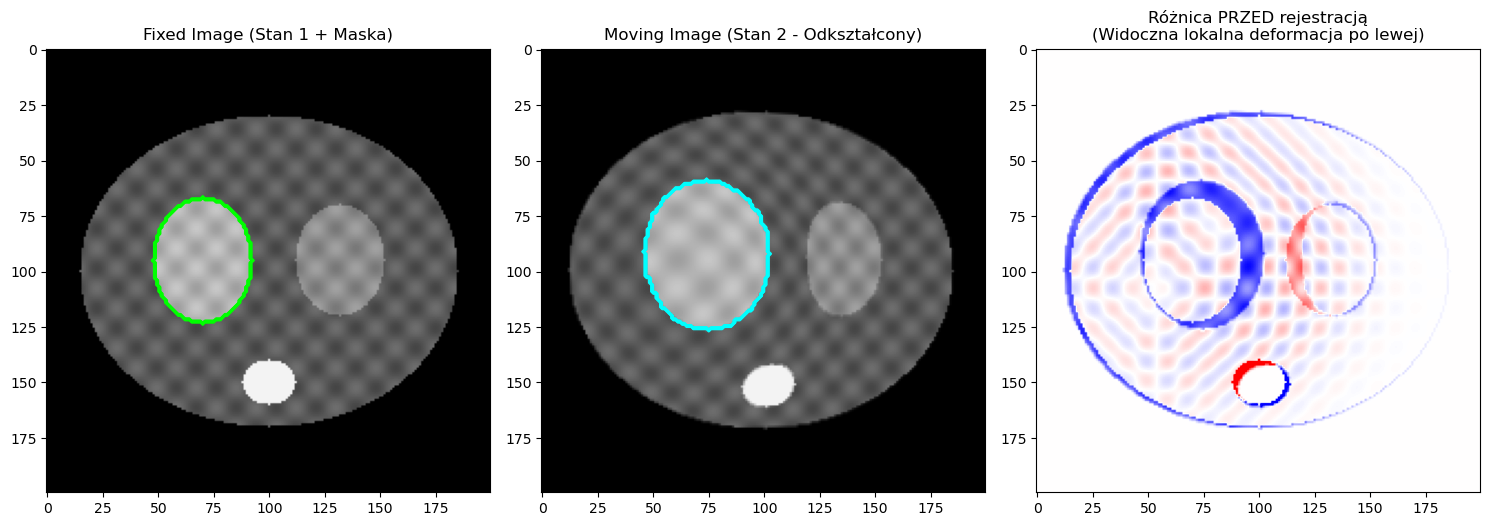

In [5]:
# Tworzymy siatkę współrzędnych 200x200 pikseli
H, W = 200, 200
y, x = np.mgrid[0:H, 0:W].astype(np.float32)

# 1. Struktury anatomiczne (Fixed Image - stan wyjściowy)
body = (((x - 100) / 85.0)**2 + ((y - 100) / 70.0)**2) <= 1.0
spine = (((x - 100) / 12.0)**2 + ((y - 150) / 10.0)**2) <= 1.0       # Sztywny kręgosłup
organ_left = (((x - 70) / 22.0)**2 + ((y - 95) / 28.0)**2) <= 1.0   # Narząd podlegający deformacji
organ_right = (((x - 132) / 20.0)**2 + ((y - 95) / 25.0)**2) <= 1.0 # Narząd stabilny

# Subtelna tekstura wewnętrzna, aby było widać rozciąganie tkanek
texture = 0.08 * np.sin(x * 0.35) * np.cos(y * 0.35)

fixed_np = np.zeros((H, W), dtype=np.float32)
fixed_np[body] = 0.35 + texture[body]
fixed_np[organ_left] = 0.70 + texture[organ_left]
fixed_np[organ_right] = 0.55 + texture[organ_right]
fixed_np[spine] = 0.95

# Binarna maska segmentacyjna badanego narządu
fixed_mask_np = organ_left.astype(np.uint8)

# Konwersja do obrazów SimpleITK
fixed_image = sitk.GetImageFromArray(fixed_np)
fixed_image.SetSpacing((1.0, 1.0))
fixed_image.SetOrigin((0.0, 0.0))

fixed_mask = sitk.GetImageFromArray(fixed_mask_np)
fixed_mask.CopyInformation(fixed_image)

# 2. Symulacja lokalnego odkształcenia (Pole wektorowe Gaussa wokół lewego narządu)
cx, cy = 70.0, 95.0
sigma = 32.0
gauss = np.exp(-((x - cx)**2 + (y - cy)**2) / (2 * sigma**2))

# Uwaga: SimpleITK wymaga typu float64 dla pól wektorowych!
disp_x = (-0.35 * (x - cx) * gauss - 6.0 * gauss).astype(np.float64)
disp_y = (-0.30 * (y - cy) * gauss + 4.0 * gauss).astype(np.float64)
disp_field_np = np.stack([disp_x, disp_y], axis=-1)

disp_img = sitk.GetImageFromArray(disp_field_np, isVector=True)
disp_img.CopyInformation(fixed_image)
synthetic_deform = sitk.DisplacementFieldTransform(sitk.Image(disp_img))

# Generujemy zdeformowany obraz (Moving Image) oraz jego maskę
moving_image = sitk.Resample(fixed_image, fixed_image, synthetic_deform, sitk.sitkLinear, 0.0, fixed_image.GetPixelID())
moving_mask = sitk.Resample(fixed_mask, fixed_image, synthetic_deform, sitk.sitkNearestNeighbor, 0, fixed_mask.GetPixelID())

# Wizualizacja stanu przed rejestracją
diff_before = sitk.GetArrayFromImage(fixed_image) - sitk.GetArrayFromImage(moving_image)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(fixed_np, cmap='gray', vmin=0, vmax=1)
ax[0].contour(fixed_mask_np, colors='lime', linewidths=1.5)
ax[0].set_title('Fixed Image (Stan 1 + Maska)')

ax[1].imshow(sitk.GetArrayFromImage(moving_image), cmap='gray', vmin=0, vmax=1)
ax[1].contour(sitk.GetArrayFromImage(moving_mask), colors='cyan', linewidths=1.5)
ax[1].set_title('Moving Image (Stan 2 - Odkształcony)')

ax[2].imshow(diff_before, cmap='bwr', vmin=-0.5, vmax=0.5)
ax[2].set_title('Różnica PRZED rejestracją\n(Widoczna lokalna deformacja po lewej)')
plt.tight_layout()
plt.show()

## 2. Dlaczego rejestracja sztywna (Rigid) tutaj nie wystarczy?

Zwróć uwagę na obraz różnicowy powyżej: kręgosłup na dole oraz prawy narząd pokrywają się idealnie (kolor biały = brak różnicy), natomiast lewy narząd wyraźnie zmienił rozmiar i położenie. 
Gdybyśmy użyli `Euler2DTransform` (przesunięcie i obrót całego obrazu), dopasowanie lewego narządu zepsułoby ułożenie kręgosłupa i reszty ciała. Potrzebujemy transformacji, która działa **lokalnie**.

## 3. Rejestracja Elastyczna z użyciem `BSplineTransform`

Zbudujemy teraz potok rejestracji elastycznej w SimpleITK:
1. **Inicjalizacja siatki B-splajn (`BSplineTransformInitializer`):** Dzielimy obszar obrazu siatką np. `6 x 6` węzłów kontrolnych (`transformDomainMeshSize=[6, 6]`). Każdy węzeł może przesuwać się niezależnie w osiach X i Y.
2. **Optymalizator `LBFGSB`:** Przy siatce 6x6 (z uwzględnieniem marginesów brzegowych dla splajnów 3. stopnia daje to $(6+3) \times (6+3) \times 2 = 162$ parametry!) prosty spadek gradientu byłby wolny. Algorytm quasi-Newtonowski **L-BFGS-B** jest standardem w rejestracji B-splajn, ponieważ świetnie radzi sobie z dziesiątkami lub setkami parametrów jednocześnie.
3. **Piramida wielorozdzielcza (`ShrinkFactors`):** Najpierw dopasowujemy zgrubne fałdy tkanki, a na końcu doprecyzowujemy detale.

In [9]:
# 1. Inicjalizacja siatki B-splajn (6x6 oczek kontrolnych, splajny sześcienne order=3)
mesh_size = [6, 6]
initial_bspline = sitk.BSplineTransformInitializer(
    image1=fixed_image, 
    transformDomainMeshSize=mesh_size, 
    order=3
)
print(f"Liczba optymalizowanych parametrów siatki B-splajn: {initial_bspline.GetNumberOfParameters()}")

# 2. Konfiguracja metody rejestracji
R_deform = sitk.ImageRegistrationMethod()
R_deform.SetMetricAsMeanSquares()

# Optymalizator L-BFGS-B – dedykowany do wielowymiarowych przestrzeni parametrów (B-splajn)
R_deform.SetOptimizerAsLBFGSB(
    gradientConvergenceTolerance=1e-5,
    numberOfIterations=100,
    maximumNumberOfCorrections=5,
    maximumNumberOfFunctionEvaluations=1000,
    costFunctionConvergenceFactor=1e7
)

R_deform.SetInterpolator(sitk.sitkLinear)
R_deform.SetInitialTransform(initial_bspline, inPlace=False)

# Piramida wielorozdzielcza dla stabilności
R_deform.SetShrinkFactorsPerLevel(shrinkFactors=[4, 2, 1])
R_deform.SetSmoothingSigmasPerLevel(smoothingSigmas=[2, 1, 0])
R_deform.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()

# 3. Uruchomienie rejestracji elastycznej
print("Rozpoczynam rejestrację elastyczną BSpline...")
final_bspline = R_deform.Execute(fixed_image, moving_image)
print(f"Zakończono! Powód zatrzymania: {R_deform.GetOptimizerStopConditionDescription()}")
print(f"Wartość błędu (Mean Squares) po rejestracji: {R_deform.GetMetricValue():.6f}")

Liczba optymalizowanych parametrów siatki B-splajn: 162
Rozpoczynam rejestrację elastyczną BSpline...
Zakończono! Powód zatrzymania: LBFGSBOptimizerv4: Gradient tolerance reached. Gradient tolerance is 1e-05
Wartość błędu (Mean Squares) po rejestracji: 0.000491


## 4. Weryfikacja wyników: Przenoszenie maski i wizualizacja pola wektorowego

Po uzyskaniu transformacji `final_bspline` możemy zrobić dwie rzeczy:
1. **Przenieść maskę segmentacyjną (`moving_mask`)** na obraz docelowy – pamiętając o użyciu interpolacji **Najbliższego Sąsiada (`sitkNearestNeighbor`)**, aby nie zniszczyć wartości binarnych `0` i `1`!
2. **Wyodrębnić i narysować pole wektorowe odkształceń** (`TransformToDisplacementFieldFilter`) oraz **zdeformowaną siatkę**, aby zobaczyć, jak algorytm "rozciągnął" przestrzeń.

Współczynnik Dice maski PRZED rejestracją: 0.7915
Współczynnik Dice maski PO rejestracji:    0.9821


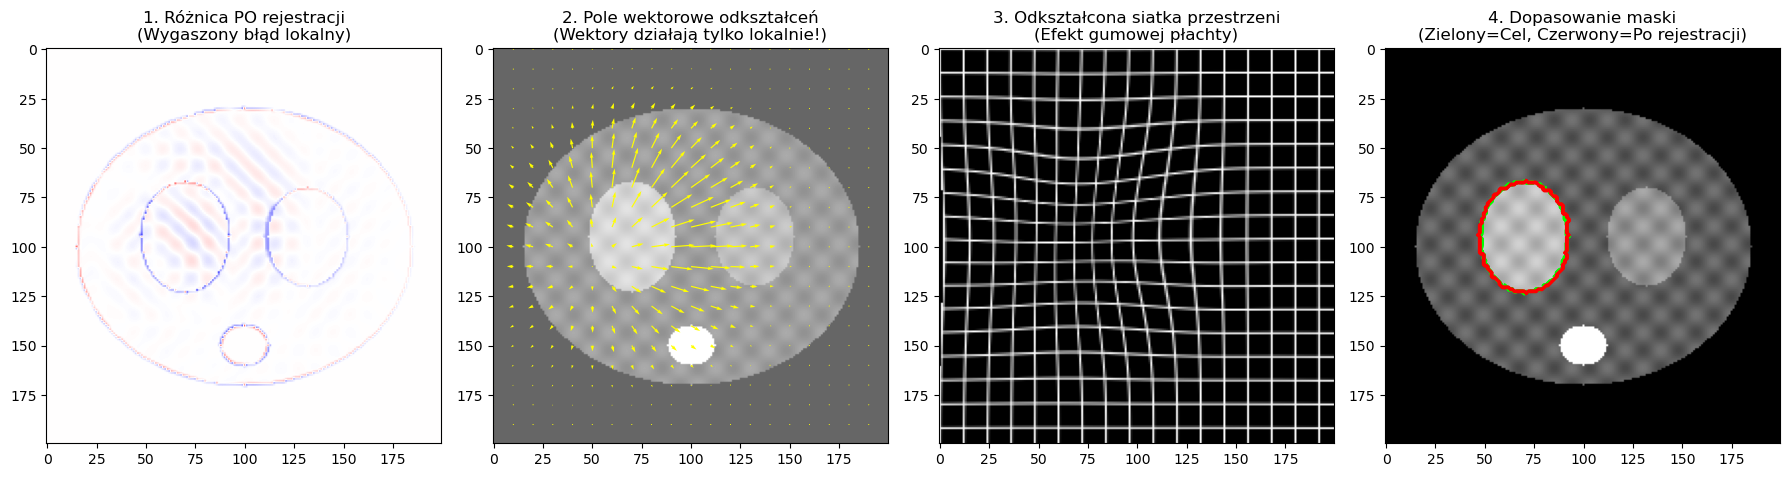

In [12]:
# 1. Resampling obrazu (interpolacja liniowa) oraz maski (interpolacja najbliższego sąsiada!)
registered_image = sitk.Resample(moving_image, fixed_image, final_bspline, sitk.sitkLinear, 0.0, moving_image.GetPixelID())
registered_mask = sitk.Resample(moving_mask, fixed_image, final_bspline, sitk.sitkNearestNeighbor, 0, moving_mask.GetPixelID())

# Obliczenie współczynnika podobieństwa Dice'a dla maski przed i po rejestracji
def dice_score(mask1, mask2):
    m1 = sitk.GetArrayFromImage(mask1) > 0
    m2 = sitk.GetArrayFromImage(mask2) > 0
    return 2.0 * np.sum(m1 & m2) / (np.sum(m1) + np.sum(m2))

print(f"Współczynnik Dice maski PRZED rejestracją: {dice_score(fixed_mask, moving_mask):.4f}")
print(f"Współczynnik Dice maski PO rejestracji:    {dice_score(fixed_mask, registered_mask):.4f}")

# 2. Ekstrakcja pola wektorowego przesunięć z transformacji B-splajn
df_filter = sitk.TransformToDisplacementFieldFilter()
df_filter.SetReferenceImage(fixed_image)
estimated_df = df_filter.Execute(final_bspline)
est_df_np = sitk.GetArrayFromImage(estimated_df) # kształt (H, W, 2)

# 3. Wygenerowanie regularnej siatki i jej odkształcenie dla wizualizacji "gumowej płachty"
grid_np = np.zeros((H, W), dtype=np.float32)
grid_np[::12, :] = 1.0
grid_np[:, ::12] = 1.0
grid_img = sitk.GetImageFromArray(grid_np)
grid_img.CopyInformation(fixed_image)
warped_grid = sitk.Resample(grid_img, fixed_image, final_bspline, sitk.sitkLinear, 0.0, grid_img.GetPixelID())

# --- WIZUALIZACJA 4 PANELI ---
diff_after = sitk.GetArrayFromImage(fixed_image) - sitk.GetArrayFromImage(registered_image)

fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))

# Panel 1: Różnica po rejestracji
ax[0].imshow(diff_after, cmap='bwr', vmin=-0.5, vmax=0.5)
ax[0].set_title('1. Różnica PO rejestracji\n(Wygaszony błąd lokalny)')

# Panel 2: Pole wektorowe (Quiver plot co 10 pikseli)
step = 10
ax[1].imshow(fixed_np, cmap='gray', alpha=0.6)
ax[1].quiver(
    x[::step, ::step], y[::step, ::step], 
    est_df_np[::step, ::step, 0], est_df_np[::step, ::step, 1],
    color='yellow', angles='xy', scale_units='xy', scale=0.8
)
ax[1].set_title('2. Pole wektorowe odkształceń\n(Wektory działają tylko lokalnie!)')

# Panel 3: Zdeformowana siatka B-splajn
ax[2].imshow(sitk.GetArrayFromImage(warped_grid), cmap='gray')
ax[2].set_title('3. Odkształcona siatka przestrzeni\n(Efekt gumowej płachty)')

# Panel 4: Przeniesienie konturu maski
ax[3].imshow(fixed_np, cmap='gray')
ax[3].contour(fixed_mask_np, colors='lime', linewidths=2, linestyles='--')
ax[3].contour(sitk.GetArrayFromImage(registered_mask), colors='red', linewidths=1.5)
ax[3].set_title('4. Dopasowanie maski\n(Zielony=Cel, Czerwony=Po rejestracji)')

plt.tight_layout()
plt.show()